In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pearsonr, spearmanr, kendalltau
from scipy.stats import ttest_ind

In [2]:
data = pd.read_csv("Womens Clothing E-Commerce Reviews.csv")

In [3]:
data

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses
...,...,...,...,...,...,...,...,...,...,...,...
23481,23481,1104,34,Great dress for many occasions,I was very happy to snag this dress at such a ...,5,1,0,General Petite,Dresses,Dresses
23482,23482,862,48,Wish it was made of cotton,"It reminds me of maternity clothes. soft, stre...",3,1,0,General Petite,Tops,Knits
23483,23483,1104,31,"Cute, but see through","This fit well, but the top was very see throug...",3,0,1,General Petite,Dresses,Dresses
23484,23484,1084,28,"Very cute dress, perfect for summer parties an...",I bought this dress for a wedding i have this ...,3,1,2,General,Dresses,Dresses


In [4]:
print(data.shape)
print(data.columns)

(23486, 11)
Index(['Unnamed: 0', 'Clothing ID', 'Age', 'Title', 'Review Text', 'Rating',
       'Recommended IND', 'Positive Feedback Count', 'Division Name',
       'Department Name', 'Class Name'],
      dtype='str')


In [5]:
data = data.rename(columns={
    'Review Text': 'Review_Text',
    'Positive Feedback Count': 'Positive_Feedback_Count',
    'Recommended IND': 'Recommended_IND'
})

data = data[
    ['Rating', 'Review_Text',
     'Positive_Feedback_Count', 'Recommended_IND']
]

data.head()

,Rating,Review_Text,Positive_Feedback_Count,Recommended_IND
0,4,Absolutely wonderful - silky and sexy and comf...,0,1
1,5,Love this dress! it's sooo pretty. i happene...,4,1
2,3,I had such high hopes for this dress and reall...,0,0
3,5,"I love, love, love this jumpsuit. it's fun, fl...",0,1
4,5,This shirt is very flattering to all due to th...,6,1


In [6]:
data = data.dropna(subset=[
    'Review_Text',
    'Rating',
    'Positive_Feedback_Count'
])

data = data.drop_duplicates()

print("Dataset shape:", data.shape)
print(data.isnull().sum())

Dataset shape: (22638, 4)
Rating                     0
Review_Text                0
Positive_Feedback_Count    0
Recommended_IND            0
dtype: int64


Apply sentiment analysis

In [7]:
# Near +1: positive sentiment
# Near 0: neutral or mixed sentiment
# Near -1: negative sentiment
import nltk
nltk.download('vader_lexicon')

from nltk.sentiment.vader import SentimentIntensityAnalyzer
sia = SentimentIntensityAnalyzer()

[nltk_data] Downloading package vader_lexicon to C:\Users\Parmar
[nltk_data]     Trupti\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


In [8]:
data['Sentiment_Score'] = data['Review_Text'].apply(
    lambda x: sia.polarity_scores(str(x))['compound']
)

data[['Review_Text', 'Sentiment_Score']].head()

,Review_Text,Sentiment_Score
0,Absolutely wonderful - silky and sexy and comf...,0.8932
1,Love this dress! it's sooo pretty. i happene...,0.9729
2,I had such high hopes for this dress and reall...,0.9427
3,"I love, love, love this jumpsuit. it's fun, fl...",0.5727
4,This shirt is very flattering to all due to th...,0.9291


Classify reviews by sentiment

In [9]:
def classify_sentiment(score):
    if score >= 0.05:
        return 'Positive'
    elif score <= -0.05:
        return 'Negative'
    else:
        return 'Neutral'

data['Sentiment'] = data['Sentiment_Score'].apply(
    classify_sentiment
)

data[['Rating', 'Sentiment_Score', 'Sentiment']].head()

,Rating,Sentiment_Score,Sentiment
0,4,0.8932,Positive
1,5,0.9729,Positive
2,3,0.9427,Positive
3,5,0.5727,Positive
4,5,0.9291,Positive


In [10]:
print(data['Sentiment'].value_counts())

Sentiment
Positive    20984
Negative     1377
Neutral       277
Name: count, dtype: int64


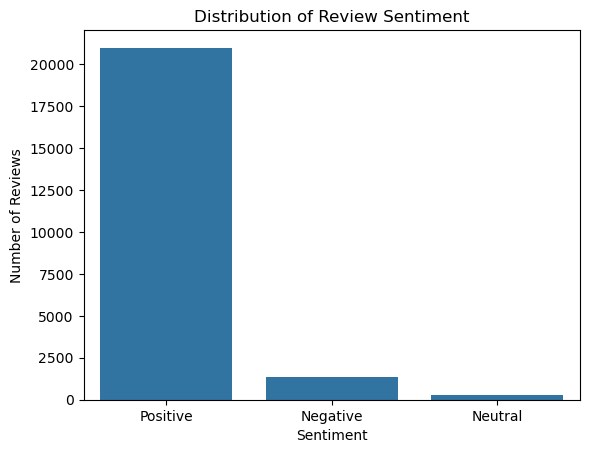

In [11]:
sns.countplot(data=data, x='Sentiment')
plt.title('Distribution of Review Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')
plt.show()

Calculate average sentiment for each rating

In [12]:
rating_sentiment = data.groupby('Rating').agg(
    Average_Sentiment=('Sentiment_Score', 'mean'),
    Average_Feedback=('Positive_Feedback_Count', 'mean'),
    Review_Count=('Rating', 'size')
)

print(rating_sentiment)

        Average_Sentiment  Average_Feedback  Review_Count
Rating                                                   
1                0.207905          3.548112           821
2                0.399738          3.360232          1549
3                0.538666          3.198725          2823
4                0.744367          2.488386          4908
5                0.853324          2.408710         12537


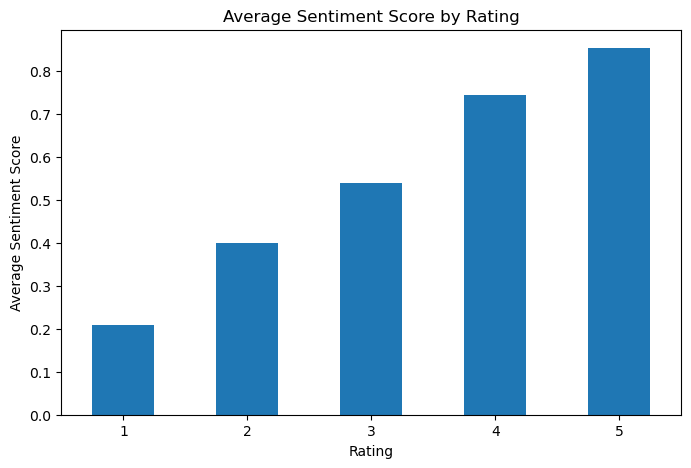

In [13]:
rating_sentiment['Average_Sentiment'].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Average Sentiment Score by Rating')
plt.xlabel('Rating')
plt.ylabel('Average Sentiment Score')
plt.xticks(rotation=0)
plt.show()

Analyze positive feedback counts

In [14]:
data['Log_Feedback'] = np.log1p(
    data['Positive_Feedback_Count']
)

print(data[
    ['Positive_Feedback_Count', 'Log_Feedback']
].describe())

       Positive_Feedback_Count  Log_Feedback
count             22638.000000  22638.000000
mean                  2.630930      0.771654
std                   5.786468      0.892760
min                   0.000000      0.000000
25%                   0.000000      0.000000
50%                   1.000000      0.693147
75%                   3.000000      1.386294
max                 122.000000      4.812184


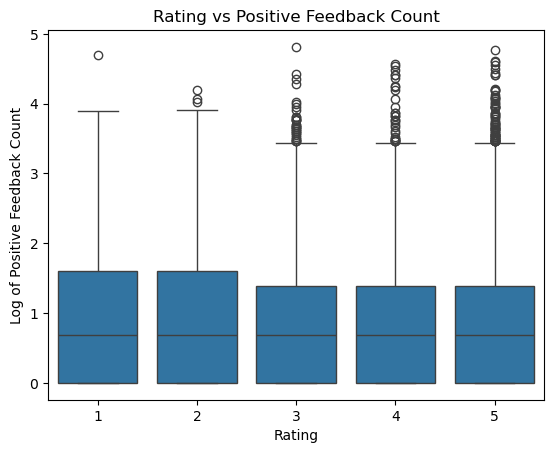

In [15]:
sns.boxplot(
    data=data,
    x='Rating',
    y='Log_Feedback'
)

plt.title('Rating vs Positive Feedback Count')
plt.xlabel('Rating')
plt.ylabel('Log of Positive Feedback Count')
plt.show()

Calculate correlation

In [16]:
pairs = [
    ('Rating', 'Log_Feedback'),
    ('Sentiment_Score', 'Log_Feedback'),
    ('Rating', 'Sentiment_Score')
]

for col1, col2 in pairs:
    r, p = pearsonr(data[col1], data[col2])
    rho, sp = spearmanr(data[col1], data[col2])

    print(f"\n{col1} vs {col2}")
    print("Pearson correlation:", round(r, 4))
    print("Pearson p-value:", p)
    print("Spearman correlation:", round(rho, 4))
    print("Spearman p-value:", sp)


Rating vs Log_Feedback
Pearson correlation: -0.0752
Pearson p-value: 9.39364786416481e-30
Spearman correlation: -0.0595
Spearman p-value: 3.3014769205436927e-19

Sentiment_Score vs Log_Feedback
Pearson correlation: -0.0229
Pearson p-value: 0.0005729354316253426
Spearman correlation: 0.024
Spearman p-value: 0.0003088855789063753

Rating vs Sentiment_Score
Pearson correlation: 0.4655
Pearson p-value: 0.0
Spearman correlation: 0.4272
Spearman p-value: 0.0


Perform a statistical test

In [17]:
positive = data.loc[
    data['Sentiment'] == 'Positive',
    'Log_Feedback'
]

negative = data.loc[
    data['Sentiment'] == 'Negative',
    'Log_Feedback'
]

t_stat, p_value = ttest_ind(
    positive,
    negative,
    equal_var=False
)

print("Positive reviews average feedback:",
      positive.mean())

print("Negative reviews average feedback:",
      negative.mean())

print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("The difference is statistically significant.")
else:
    print("The difference is not statistically significant.")

Positive reviews average feedback: 0.7642816587424137
Negative reviews average feedback: 0.889228584563433
T-statistic: -4.769090862691214
P-value: 2.0256617231801606e-06
The difference is statistically significant.


Create a correlation heatmap

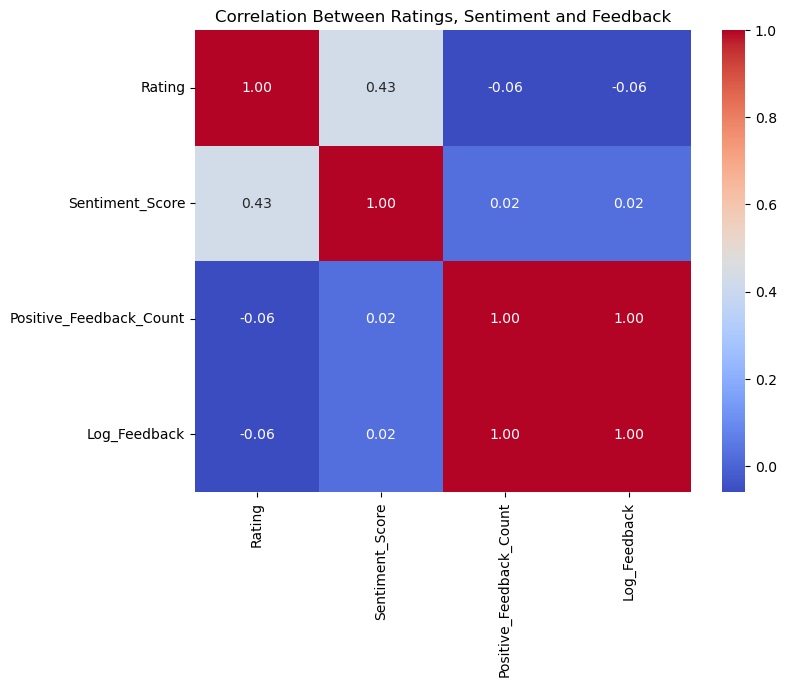

In [18]:
corr = data[
    ['Rating', 'Sentiment_Score',
     'Positive_Feedback_Count', 'Log_Feedback']
].corr(method='spearman')

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Between Ratings, Sentiment and Feedback')
plt.show()

Final summary

In [19]:
print("Average Rating:",
      round(data['Rating'].mean(), 2))

print("Average Sentiment Score:",
      round(data['Sentiment_Score'].mean(), 3))

print("Average Positive Feedback:",
      round(data['Positive_Feedback_Count'].mean(), 2))

print("\nSentiment Distribution:")
print(data['Sentiment'].value_counts())

print("\nAverage Sentiment by Rating:")
print(data.groupby('Rating')['Sentiment_Score'].mean())

print("\nAverage Feedback by Rating:")
print(data.groupby('Rating')['Positive_Feedback_Count'].mean())

Average Rating: 4.18
Average Sentiment Score: 0.736
Average Positive Feedback: 2.63

Sentiment Distribution:
Sentiment
Positive    20984
Negative     1377
Neutral       277
Name: count, dtype: int64

Average Sentiment by Rating:
Rating
1    0.207905
2    0.399738
3    0.538666
4    0.744367
5    0.853324
Name: Sentiment_Score, dtype: float64

Average Feedback by Rating:
Rating
1    3.548112
2    3.360232
3    3.198725
4    2.488386
5    2.408710
Name: Positive_Feedback_Count, dtype: float64
